# Ocupación de inmuebles: allanamientos de morada y usurpaciones por 100.000 habitantes

In [ ]:
# Parámetros de la gráfica
SLUG = "vivienda"  # carpeta en research/temas/
GRAFICA_ID = "ocupacion-inmuebles"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Ocupación de inmuebles: allanamientos de morada y usurpaciones por 100.000 habitantes"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "solo_espana"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "hechos conocidos por 100.000 habitantes"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 1  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Cuántos hechos de allanamiento de morada y de usurpación de inmuebles conocen cada año las fuerzas de seguridad, por cada 100.000 habitantes. Son los delitos con los que el Ministerio del Interior registra lo que en el debate público se llama «ocupación» de inmuebles.

**Qué mezcla.** La serie suma dos delitos del Código Penal que el Ministerio del Interior no publica por separado:
- **Allanamiento de morada** (arts. 202 y 203): entrar o mantenerse en la morada de otra persona sin su consentimiento.
- **Usurpación de inmuebles** (art. 245): ocupar un inmueble ajeno que no es morada, con violencia o intimidación o sin ellas, o mantenerse en él contra la voluntad de su titular. Abarca inmuebles residenciales o no (por ejemplo, una vivienda vacía o un local), no solo viviendas.

Por eso **no mide solo la ocupación de viviendas** ni cuántos inmuebles están ocupados en un momento dado: cuenta hechos que se registran en el año.

**Cómo se lee.** Un valor de 30 significa que, ese año, las fuerzas de seguridad conocieron 30 hechos de estos dos delitos por cada 100.000 habitantes. Se divide entre la población para que los años sean comparables.

**Limitaciones.**
- Son *hechos conocidos*: las infracciones que llegan a las fuerzas de seguridad por denuncia o por actuación propia. No incluye lo que no se denuncia ni se detecta.
- Una subida o bajada puede deberse a un cambio en el número de casos, en la frecuencia con que se denuncian o en cómo se registran; la serie no permite separarlos.
- El Sistema Estadístico de Criminalidad cuenta los hechos de la Policía Nacional, la Guardia Civil, las policías autonómicas y las policías locales que facilitan datos; esta última participación puede variar con los años.
- Solo España y desde 2010, el primer año de la tabla del Ministerio del Interior.

## 2. Descarga

- **Hechos conocidos:** Ministerio del Interior, Sistema Estadístico de Criminalidad, tabla «Allanamiento / Usurpación de inmuebles» (series anuales por comunidades autónomas), fila `TOTAL NACIONAL`.
- **Población:** INE, Cifras de Población (Estadística Continua de Población), serie `ECP320` (total nacional, todas las edades), población a 1 de enero de cada año.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import ine, interior
from lib.tipos import FuenteMeta


def descargar():
    """Devuelve (hechos conocidos, población a 1 de enero) y sus fuentes."""
    hechos, f_hechos = interior.get("hechos_conocidos", {"TOTAL NACIONAL": "espana"}, desde=DESDE)
    poblacion, f_pob = ine.get({"ECP320": "espana"}, agregacion="primero", desde=DESDE)
    return hechos, f_hechos, poblacion, f_pob


hechos, f_hechos, poblacion, f_pob = descargar()

## 3. Transformación

La tasa es los hechos conocidos de cada año entre la población residente a 1 de enero de ese mismo año, multiplicado por 100.000. La tabla muestra los tres datos para poder comprobarlo.

In [ ]:
h = hechos.set_index("periodo")["valor"]
p = poblacion.set_index("periodo")["valor"]
anios = h.index.intersection(p.index)
tasa = h.loc[anios] / p.loc[anios] * 100_000
df = pd.DataFrame({"serie": "espana", "periodo": anios, "valor": tasa.values})
assert df["valor"].between(1, 200).all(), "tasa fuera de rango: ¿unidades?"

tabla = pd.DataFrame({"Hechos conocidos": h.loc[anios], "Población a 1 de enero": p.loc[anios].round(0), "Por 100.000": tasa.round(1)})
display(tabla)

PRIMER_ANIO = int(anios.min())
HOY = f_hechos[0].fecha_consulta
fuentes = [
    FuenteMeta("espana", interior.ORGANISMO,
               "Sistema Estadístico de Criminalidad, tabla 11001 (hechos conocidos, TOTAL NACIONAL) ÷ INE ECP320 (población a 1 de enero) × 100.000",
               f_hechos[0].url, HOY),
]

NOTAS = [
    "Mezcla dos delitos: allanamiento de morada (arts. 202 y 203 del Código Penal) y usurpación de inmuebles (art. 245, con o sin violencia o intimidación y sean o no viviendas). El Ministerio del Interior no publica el desglose por delito ni por tipo de inmueble, así que la serie no mide solo la ocupación de viviendas.",
    "Hechos conocidos: infracciones penales que conocen las fuerzas de seguridad por denuncia o por actuación propia (Policía Nacional, Guardia Civil, policías autonómicas y las policías locales que facilitan datos al Sistema Estadístico de Criminalidad). No incluye los hechos que no se denuncian ni se detectan. Una variación puede deberse a un cambio en los casos, en las denuncias o en el registro.",
    "Tasa por 100.000 habitantes: hechos conocidos entre la población residente a 1 de enero del mismo año (INE, Cifras de Población, serie ECP320, total nacional y todas las edades), por 100.000. Los hechos son del total nacional publicado por el Ministerio del Interior (tabla 11001, que incluye los pocos hechos registrados en el extranjero).",
    f"La tabla del Ministerio del Interior empieza en 2010: los años anteriores a {PRIMER_ANIO} quedan sin dato.",
    "Solo España: no se ha localizado en Eurostat ni en la OCDE una serie comparable de ocupación de inmuebles entre países.",
]
for n in NOTAS:
    print("-", n)

,Hechos conocidos,Población a 1 de enero,Por 100.000
periodo,,,
2010,2702.0,46486621.0,5.8
2011,3849.0,46667175.0,8.2
2012,6233.0,46818216.0,13.3
2013,7739.0,46712650.0,16.6
2014,10084.0,46495744.0,21.7
2015,10376.0,46425722.0,22.3
2016,9998.0,46418884.0,21.5
2017,10619.0,46497393.0,22.8
2018,12214.0,46645070.0,26.2


- Mezcla dos delitos: allanamiento de morada (arts. 202 y 203 del Código Penal) y usurpación de inmuebles (art. 245, con o sin violencia o intimidación y sean o no viviendas). El Ministerio del Interior no publica el desglose por delito ni por tipo de inmueble, así que la serie no mide solo la ocupación de viviendas.
- Hechos conocidos: infracciones penales que conocen las fuerzas de seguridad por denuncia o por actuación propia (Policía Nacional, Guardia Civil, policías autonómicas y las policías locales que facilitan datos al Sistema Estadístico de Criminalidad). No incluye los hechos que no se denuncian ni se detectan. Una variación puede deberse a un cambio en los casos, en las denuncias o en el registro.
- Tasa por 100.000 habitantes: hechos conocidos entre la población residente a 1 de enero del mismo año (INE, Cifras de Población, serie ECP320, total nacional y todas las edades), por 100.000. Los hechos son del total nacional publicado por el Ministerio del Interior (tabla 11001

## 4. Visualización

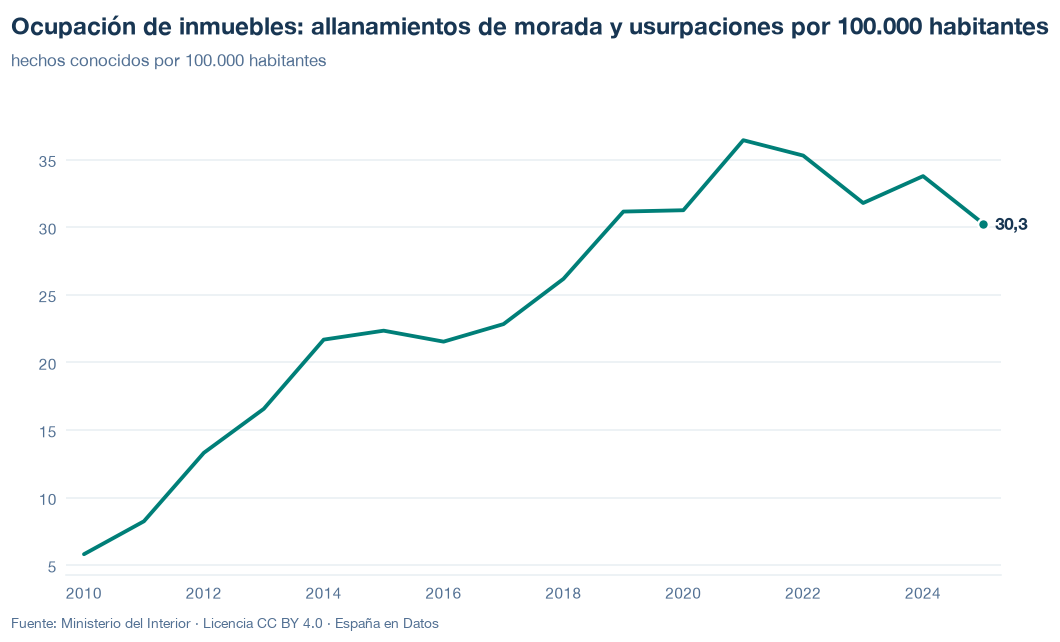

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/ocupacion-inmuebles.json y data/ocupacion-inmuebles.csv


## 6. Fuentes, notas y licencia

- Ministerio del Interior, Sistema Estadístico de Criminalidad: tabla «Allanamiento / Usurpación de inmuebles. Hechos conocidos» (11001), portal estadístico de criminalidad.
- INE, Cifras de Población (Estadística Continua de Población), serie `ECP320`.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.